# Editing a Learned Mind

*The Mathematics of Machine Intelligence · Chapter 28*

Can a mind be fixed or taught by changing its connections directly, instead of by training it?

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Check an edit against the old pairs it was not meant to touch, and against a test it was not tuned on, before believing it taught anything.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 28, Editing a Learned Mind: executable mathematics and reader-facing teaching content."""
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
KEYS_OVERLAP = np.array([[1, 1, 1, 1], [1, 1, -1, -1], [1, 1, 1, -1], [1, -1, 1, 1]], dtype=float) / 2
KEYS_RIGHT = np.array([[1, 1, 1, 1], [1, 1, -1, -1], [1, -1, 1, -1], [1, -1, -1, 1]], dtype=float) / 2
ANSWERS = np.eye(5)[:4]
NEW_KEYS = {1: np.array([0.5, 0.5, -0.5, 0.5]), 2: np.array([0.5, -0.5, -0.5, -0.5]), 3: np.array([1.0, 0.0, 0.0, 0.0])}
NEW_KEY_LABELS = ["chapter's new key", 'mirror key', 'single-unit key']

def store(keys, answers, eta=1.0):
    """W = sum over pairs of eta * v k^T (the chapter's storage rule)."""
    return eta * sum((np.outer(v, k) for v, k in zip(answers, keys)))

def recall(table, key):
    return table @ key

def ghost_picture(asked=3, keys='overlapping'):
    key_set = KEYS_OVERLAP if keys == 'overlapping' else KEYS_RIGHT
    table = store(key_set, ANSWERS)
    out = recall(table, key_set[asked - 1])
    gram = key_set @ key_set.T
    fig, ax = panels()
    colours = [TEAL if i == asked - 1 else GOLD if abs(out[i]) > 1e-12 else GREY for i in range(5)]
    bars = ax[0].bar([f'slot {i + 1}' for i in range(5)], out, color=colours, width=0.6)
    for bar, value in zip(bars, out):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, value + (0.06 if value >= 0 else -0.06), sig(value), va='bottom' if value >= 0 else 'top')
    ax[0].axhline(0, color=GREY, linewidth=1)
    ax[0].set(ylabel='strength returned', title=f'Asking the table with key {asked}', ylim=(-0.85, 1.35))
    image = ax[1].imshow(gram, cmap='RdBu_r', vmin=-1, vmax=1)
    ax[1].set_xticks(range(4), [f'{i + 1}' for i in range(4)])
    ax[1].set_yticks(range(4), [f'{i + 1}' for i in range(4)])
    for i in range(4):
        for j in range(4):
            ax[1].text(j, i, sig(gram[i, j]), ha='center', va='center', fontsize=10, color='black', bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1, 'alpha': 0.75})
    ax[1].add_patch(plt.Rectangle((-0.5, asked - 1.5), 4, 1, fill=False, edgecolor=NAVY, linewidth=3))
    ax[1].set(xlabel='key', ylabel='asked key', title='Overlaps between keys')
    fig.colorbar(image, ax=ax[1], shrink=0.7, label='overlap')
    ghosts = {i + 1: out[i] for i in range(5) if i != asked - 1 and abs(out[i]) > 1e-12}
    biggest = max((abs(v) for v in ghosts.values()), default=0.0)
    metrics = {'Right answer': sig(out[asked - 1]), 'Ghost slots': str(len(ghosts)), 'Largest ghost': sig(biggest), 'Right answer minus largest ghost': sig(out[asked - 1] - biggest)}
    if ghosts:
        parts = ', '.join((f'slot {s} gets {sig(v)}' for s, v in ghosts.items()))
        summary = f"With {keys} keys, key {asked} returns its own answer at {sig(out[asked - 1])} and ghosts: {parts}. Each ghost equals the overlap of key {asked} with that slot's key."
    else:
        summary = f'With {keys} keys, key {asked} returns exactly its own answer and no ghost, because every other key has overlap 0 with it.'
    overlaps = [f'k{i + 1}.k{asked} = {sig(gram[i, asked - 1])}' for i in range(4) if i != asked - 1]
    calc = f'W k{asked} = v{asked} + sum of v_i (k_i . k{asked}) over the other keys; here ' + ', '.join(overlaps) + '. Own overlap k.k = 1.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def operate(table, operation):
    """Weaken (subtract pair 3's product), strengthen (add it), both in turn, or neither."""
    product = np.outer(ANSWERS[2], KEYS_OVERLAP[2])
    out = table.copy()
    if operation == 'weaken':
        out = out - product
    elif operation == 'weaken then strengthen':
        out = out - product + product
    elif operation == 'strengthen':
        out = out + product
    return out
TABLE_CASES = ['holds pair 3', 'never held pair 3']
OPERATIONS = ['none', 'weaken', 'weaken then strengthen', 'strengthen']

def base_table(case):
    if case == 'holds pair 3':
        return store(KEYS_OVERLAP, ANSWERS)
    return store(KEYS_OVERLAP[[0, 1, 3]], ANSWERS[[0, 1, 3]])

def weaken_picture(operation='weaken', case='holds pair 3'):
    table = operate(base_table(case), operation)
    slot3 = table[2] @ KEYS_OVERLAP.T
    fig, ax = panels()
    colours = [GOLD, GOLD, TEAL, GREY]
    bars = ax[0].bar(['key 1', 'key 2', 'key 3', 'key 4'], slot3, color=colours, width=0.6)
    for bar, value in zip(bars, slot3):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, value + (0.05 if value >= 0 else -0.05), sig(value), va='bottom' if value >= 0 else 'top')
    ax[0].axhline(0, color=GREY, linewidth=1)
    ax[0].set(ylabel='slot 3 of the answer', title=f'{operation} ({case})', ylim=(-1.15, 2.85))
    ax[0].title.set_fontsize(10)
    xs, labels = ([], [])
    for ci, c in enumerate(TABLE_CASES):
        for oi, op in enumerate(OPERATIONS):
            t = operate(base_table(c), op)
            v = t[2] @ KEYS_OVERLAP[2]
            x = ci * 5 + oi
            xs.append(x)
            ax[1].bar(x, v, color=TEAL if c == 'holds pair 3' else TERRA, width=0.7, alpha=0.55 if c != case or op != operation else 1.0)
            if c == case and op == operation:
                ring(ax[1], x, v)
    ax[1].set_xticks(xs, ['none', 'weaken', 'weaken,\nstrengthen', 'strengthen'] * 2, fontsize=7, rotation=45, ha='right')
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].axhline(1, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 1.5, 2.55, 'holds pair 3', color=TEAL)
    tag(ax[1], 6.5, 2.55, 'never held it', color=TERRA)
    ax[1].set(ylabel='slot 3 returned for key 3', title='Every case', ylim=(-1.15, 2.85))
    key3 = slot3[2]
    exact = np.allclose(table, base_table(case))
    metrics = {'Slot 3 for key 3': sig(key3), 'Slot 3 ghost for key 1': sig(slot3[0]), 'Table equals the starting table': 'yes' if exact else 'no', 'Pair 3 answer is': 'present' if abs(key3 - 1) < 1e-09 else 'gone' if abs(key3) < 1e-09 else 'changed'}
    summary = f"Operation '{operation}' on a table that {case} returns {sig(key3)} in slot 3 for key 3 and {sig(slot3[0])} for key 1. The table {('equals' if exact else 'does not equal')} its starting table."
    calc = f'One step adds eta v3 k3^T with eta = -1 to weaken and +1 to strengthen. Slot 3 for key j is eta (k3 . kj) plus whatever was stored: key 3 gives {sig(key3)}, key 1 gives {sig(slot3[0])}, key 2 gives {sig(slot3[1])}, key 4 gives {sig(slot3[3])}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def insert_write(table, key, value, z):
    """W' = W + (v - W k) z^T / (z^T k)."""
    return table + np.outer(value - table @ key, z) / (z @ key)

def key_covariance(keys):
    return keys.T @ keys

def insert_damage(new_key, rome):
    """Return the table before and after, and the change in answer for each old key."""
    table = store(KEYS_OVERLAP, ANSWERS)
    value = np.eye(5)[4]
    z = np.linalg.solve(key_covariance(KEYS_OVERLAP), new_key) if rome else new_key
    after = insert_write(table, new_key, value, z)
    change = (after - table) @ KEYS_OVERLAP.T
    return (table, after, change)

def insert_picture(write='naive', new_key=1):
    key = NEW_KEYS[new_key]
    rome = write == 'corrected'
    table, after, change = insert_damage(key, rome)
    per_key = np.linalg.norm(change, axis=0)
    total = float(np.linalg.norm(change))
    fig, ax = panels()
    bars = ax[0].bar([f'old key {i + 1}' for i in range(4)], per_key, color=[TERRA if v > 1e-09 else GREY for v in per_key], width=0.6)
    for bar, v in zip(bars, per_key):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.015, sig(v), va='bottom')
    ax[0].set(ylabel='size of the change in the answer', title=f'{write} write: damage to each old pair', ylim=(0, 1.0))
    width = 0.34
    for i, k in enumerate(NEW_KEYS):
        values = [float(np.linalg.norm(insert_damage(NEW_KEYS[k], r)[2])) for r in (False, True)]
        for j, (v, colour) in enumerate(zip(values, [TERRA, TEAL])):
            ax[1].bar(i + (j - 0.5) * width, v, width=width, color=colour, alpha=1.0 if k == new_key else 0.5, label=['naive', 'corrected'][j] if i == 0 else None)
            tag(ax[1], i + (j - 0.5) * width, v + 0.04, sig(v), va='bottom', fontsize=9)
    ring(ax[1], new_key - 1 + ((1 if rome else 0) - 0.5) * width, total)
    ax[1].set_xticks(range(3), ["chapter's\nnew key", 'mirror\nkey', 'single-unit\nkey'])
    ax[1].set(ylabel='total size of damage', title='Both writes, three new keys', ylim=(0, 1.9))
    ax[1].legend(fontsize=9, loc='upper left')
    new_back = after @ key
    metrics = {'Total damage to old pairs': sig(total), 'Largest single-key change': sig(per_key.max()), 'Old keys touched': str(int(np.sum(per_key > 1e-09))), 'New key returns slot 5 at': sig(new_back[4])}
    naive_total = float(np.linalg.norm(insert_damage(key, False)[2]))
    corrected_total = float(np.linalg.norm(insert_damage(key, True)[2]))
    summary = f'Both writes make the new key return slot 5 at exactly 1. For the {NEW_KEY_LABELS[new_key - 1]} the naive write damages old pairs by {sig(naive_total)} in total and the corrected write by {sig(corrected_total)}, touching {int(np.sum(per_key > 1e-09))} old keys in the selected case.'
    calc = f'Leftover v* - W k* = {np.round(np.eye(5)[4] - table @ key, 3).tolist()}. Change for old key j is (leftover) times (z . kj) / (z . k*). Total damage = square root of the sum of squared changes = {sig(total)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
POOL = 256
EDITS = 20
SHARED_MIX = 0.7

def key_pool(rng, d, shared, n):
    g = rng.normal(size=(n, d))
    if shared:
        mean = np.zeros(d)
        mean[0] = 1.0
        g = SHARED_MIX * g / np.sqrt(d) + mean
    return g / np.linalg.norm(g, axis=1, keepdims=True)

def sequential_edits(d, shared, corrected, edits=EDITS, seed=0):
    """One run: insert random unit pairs one after another. Returns drift and earlier-insert error after each edit."""
    rng = np.random.default_rng(seed)
    pool = key_pool(rng, d, shared, POOL)
    cov = pool.T @ pool / POOL
    w0 = rng.normal(size=(d, d)) / np.sqrt(d)
    w = w0.copy()
    base = np.linalg.norm(pool @ w0.T)
    drift = np.full(edits + 1, np.nan)
    error = np.full(edits + 1, np.nan)
    keys, values = ([], [])
    for e in range(1, edits + 1):
        k = key_pool(rng, d, shared, 1)[0]
        v = rng.normal(size=d)
        v /= np.linalg.norm(v)
        z = np.linalg.solve(cov, k) if corrected else k
        w = insert_write(w, k, v, z)
        drift[e] = np.linalg.norm(pool @ (w - w0).T) / base
        if keys:
            error[e] = np.sqrt(np.mean([np.sum((w @ kk - vv) ** 2) for kk, vv in zip(keys, values)]))
        keys.append(k)
        values.append(v)
    return (drift, error)

@lru_cache(maxsize=None)
def pile_up(d, shared, corrected, runs=50):
    drifts, errors = ([], [])
    for s in range(runs):
        dr, er = sequential_edits(d, shared, corrected, seed=1000 + s)
        drifts.append(dr)
        errors.append(er)
    return (np.mean(drifts, axis=0), np.mean(errors, axis=0))

def pileup_picture(edits=20, dimension=64):
    fig, ax = panels()
    styles = [(True, False, TERRA, 'solid'), (True, True, TEAL, 'solid'), (False, False, TERRA, 'dashed'), (False, True, TEAL, 'dashed')]
    labels = ['shared direction, naive', 'shared direction, corrected', 'unrelated keys, naive', 'unrelated keys, corrected']
    values = {}
    x = np.arange(1, EDITS + 1)
    for (shared, corrected, colour, style), label in zip(styles, labels):
        drift, error = pile_up(dimension, shared, corrected)
        values[shared, corrected] = (drift[edits], error[edits])
        ax[0].plot(x, drift[1:], color=colour, linestyle=style, linewidth=2, label=label)
        ax[1].plot(x[1:], error[2:], color=colour, linestyle=style, linewidth=2)
        ring(ax[0], edits, drift[edits])
        if edits >= 2:
            ring(ax[1], edits, error[edits])
    for a in ax:
        a.axvline(edits, color=NAVY, linewidth=1, linestyle='dotted')
        if dimension < EDITS:
            a.axvline(dimension, color=GREY, linewidth=1.2, linestyle='dashed')
    if dimension < EDITS:
        tag(ax[1], dimension + 0.2, ax[1].get_ylim()[1] * 0.97, 'edits = dimensions', ha='left', va='top', fontsize=9, color=GREY)
    ax[0].set(xlabel='edits so far', ylabel="drift (share of the layer's output size)", title='Old behavior moves')
    ax[1].set(xlabel='edits so far', ylabel='earlier inserts: RMS answer error', title='Earlier inserts go wrong')
    ax[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    shared_naive, shared_fixed = (values[True, False], values[True, True])
    undefined = 'undefined (no earlier insert yet)'
    metrics = {'Drift, shared keys, naive': sig(shared_naive[0]), 'Drift, shared keys, corrected': sig(shared_fixed[0]), 'Earlier-insert error, shared keys, naive': undefined if edits < 2 else sig(shared_naive[1]), 'Earlier-insert error, shared keys, corrected': undefined if edits < 2 else sig(shared_fixed[1])}
    summary = f'After {edits} edits in {dimension} dimensions (mean of 50 seeded runs) drift with keys sharing a direction is {sig(shared_naive[0])} for the naive write and {sig(shared_fixed[0])} corrected. With unrelated keys it is {sig(values[False, False][0])} and {sig(values[False, True][0])}. No line stays near zero.'
    calc = "Each edit is W' = W + (v - W k) z^T / (z^T k) with z = k (naive) or z = C^-1 k (corrected, C fixed from 256 sample keys). Drift = |(W - W0) X| / |W0 X| over the same 256 keys X. Error = root mean square of |W k - v| over earlier inserts."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def direction_edit(w, u, mask, c):
    """W' = W - c u (m * (u^T W)): scale by (1 - c) the write along u in the chosen columns."""
    return w - c * np.outer(u, mask * (u @ w))
STRENGTHS = np.array([3.0, 2.0, 1.0, 0.0, 0.0, 0.0])

def example_layer():
    """A six-neuron layer whose neurons write along the unit direction u with the chapter's strengths (3, 2, 1, 0, 0, 0)."""
    rng = np.random.default_rng(28)
    u = np.array([1.0, 0.0, 0.0])
    rest = rng.normal(size=(2, 6))
    w = np.vstack([STRENGTHS, rest])
    return (w, u)

def direction_picture(c=1, columns=2):
    w, u = example_layer()
    mask = np.array([1.0] * columns + [0.0] * (6 - columns))
    edited = direction_edit(w, u, mask, c)
    after = u @ edited
    fig, ax = panels()
    xs = np.arange(6)
    ax[0].bar(xs - 0.2, STRENGTHS, width=0.4, color=GREY, label='before')
    ax[0].bar(xs + 0.2, after, width=0.4, color=TERRA if c > 1 else TEAL, label='after')
    for x, v in zip(xs, after):
        if abs(v) > 1e-12:
            tag(ax[0], x + 0.2, v + (0.8 if v >= 0 else -0.8), sig(v), va='bottom' if v >= 0 else 'top', fontsize=9)
    ax[0].axhline(0, color=GREY, linewidth=1)
    ax[0].set_xticks(xs, [f'n{i + 1}' for i in range(6)])
    ax[0].set(ylabel='write along u', title=f'Strengths before and after, c = {sig(c)}', ylim=(-17, 5))
    ax[0].legend(fontsize=9, loc='lower left')
    grid = np.linspace(0, 6, 61)
    for cols, colour, style in [(2, TEAL, 'solid'), (6, DARK_GOLD, 'dashed')]:
        m = np.array([1.0] * cols + [0.0] * (6 - cols))
        totals = [float(np.sum(u @ direction_edit(w, u, m, cc))) for cc in grid]
        ax[1].plot(grid, totals, color=colour, linestyle=style, linewidth=3 if cols == columns else 1.6, label=f'first {cols} neurons edited' if cols == 2 else 'all 6 neurons edited')
    total = float(after.sum())
    ring(ax[1], c, total)
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].set(xlabel='dial c', ylabel='total write along u (all neurons at 1)', title='Total write against the dial')
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    metrics = {'Multiplier on chosen columns': sig(1 - c), 'Strengths after': '(' + ', '.join((sig(v) for v in after)) + ')', 'Total write along u': sig(total)}
    summary = f"At c = {sig(c)} the chosen columns' write along u is multiplied by {sig(1 - c)}, so the strengths become ({', '.join((sig(v) for v in after))}). The total write is {sig(total)}, against 6 before."
    calc = f"W' = W - c u (m times (u^T W)). Chosen columns: 1 - {sig(c)} = {sig(1 - c)} times their old strength (3, 2, 1 where chosen). Unchosen columns keep theirs. Sum = {sig(total)}. The change is one outer product, so its rank is {int(np.linalg.matrix_rank(edited - w))}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def feedback_multiplier(growth, c):
    return 1 + growth * (1 - c)

def feedback_path(growth, c, rounds=8):
    return feedback_multiplier(growth, c) ** np.arange(rounds + 1)

def feedback_picture(c=6, growth=0.35):
    path = feedback_path(growth, c)
    m = feedback_multiplier(growth, c)
    fig, ax = panels()
    rounds = np.arange(len(path))
    for g, colour in [(0.1, GREY), (0.35, TEAL), (0.7, TERRA)]:
        p = feedback_path(g, c)
        mag = np.maximum(np.abs(p), 1e-06)
        chosen = g == growth
        ax[0].plot(rounds, mag, color=NAVY if chosen else colour, linewidth=3 if chosen else 1.4, linestyle='solid' if chosen else 'dashed', label=f'growth {g * 100:g} percent')
        ax[0].scatter(rounds, mag, s=30, zorder=4, facecolors=np.where(p >= 0, NAVY if chosen else colour, 'white'), edgecolors=NAVY if chosen else colour)
    ax[0].set_yscale('log')
    ax[0].axhline(1, color=GREY, linewidth=1, linestyle='dotted')
    ax[0].set(xlabel='round of feedback', ylabel='size of the part along u (open dot: sign flipped)', title=f'c = {sig(c)}')
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    cs = np.linspace(0, 6, 121)
    for g, colour in [(0.1, GREY), (0.35, TEAL), (0.7, TERRA)]:
        ax[1].plot(cs, feedback_multiplier(g, cs), color=NAVY if g == growth else colour, linewidth=3 if g == growth else 1.4, linestyle='solid' if g == growth else 'dashed')
    ax[1].axhspan(-1, 1, color=TEAL, alpha=0.1)
    ax[1].axhline(0, color=GREY, linewidth=1)
    tag(ax[1], 1.3, -0.7, 'shrinks (stable)', fontsize=9, color=TEAL)
    ring(ax[1], c, m)
    ax[1].set(xlabel='dial c', ylabel='multiplier per round', title='Multiplier 1 + g(1 - c)', ylim=(-5, 2.5))
    last = path[-1]
    behaviour = 'grows' if abs(m) > 1 + 1e-12 else 'holds steady' if abs(abs(m) - 1) <= 1e-12 else 'shrinks'
    flips = ' and flips sign each round' if m < 0 else ''
    metrics = {'Multiplier per round': sig(m), 'Part along u after 8 rounds': sig(last), 'Behavior': behaviour + flips}
    summary = f'With growth {growth * 100:g} percent per round and dial c = {sig(c)}, the multiplier is {sig(m)}, so the part along u {behaviour}{flips}. After 8 rounds it is {sig(last)}.'
    calc = f'Multiplier = 1 + g(1 - c) = 1 + {sig(growth)} x (1 - {sig(c)}) = {sig(m)}. After 8 rounds: {sig(m)}^8 = {sig(last)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
ASTRA_RUNS = {10: (12.3, 87.2), 25: (14.1, 86.4), 50: (48.1, 33.1)}
UNEDITED_ON = (7.9, 93.0)
OUTSIDE = {'Toledo': (44.0, None), 'Hedwig AI': (43.6, 45.2), 'EditLens': (51.0, 48.7)}

def astra_picture(passes=50, outside='Hedwig AI'):
    score, limit = ASTRA_RUNS[passes]
    base_off, edit_off = OUTSIDE[outside]
    gain = score - UNEDITED_ON[0]
    fig, ax = panels()
    labels = ['unedited,\nthinking on', 'edited,\nthinking on', 'unedited,\nthinking off', 'edited,\nthinking off']
    values = [UNEDITED_ON[0], score, base_off, edit_off if edit_off is not None else 0]
    colours = [GREY, TEAL, GREY, TERRA]
    bars = ax[0].bar(range(4), values, color=colours, width=0.6)
    for i, (bar, v) in enumerate(zip(bars, values)):
        if i == 3 and edit_off is None:
            tag(ax[0], i, 4, 'not run', fontsize=9, color=TERRA)
        else:
            tag(ax[0], i, v + 1.2, sig(v), va='bottom')
    ax[0].set_xticks(range(4), labels, fontsize=8)
    ax[0].set(ylabel='MATH-500 score (percent)', title=f'{passes} passes; thinking off: {outside}', ylim=(0, 60))
    xs = [93.0] + [ASTRA_RUNS[p][1] for p in (10, 25, 50)]
    ys = [UNEDITED_ON[0]] + [ASTRA_RUNS[p][0] for p in (10, 25, 50)]
    ax[1].plot(xs, ys, color=GREY, linewidth=1, linestyle='dotted')
    ax[1].scatter(xs, ys, color=TEAL, s=45, zorder=4)
    for (x, y, name), (dx, dy) in zip(zip(xs, ys, ['unedited', '10 passes', '25 passes', '50 passes']), [(0, -5), (-9, -5.5), (-10, 4), (0, 5)]):
        tag(ax[1], x + dx, y + dy, name, fontsize=9)
    ring(ax[1], limit, score)
    ax[1].set_xlim(100, 25)
    ax[1].set(xlabel='answers hitting the length limit (percent)', ylabel='MATH-500 score (percent)', title='Fewer loops, higher score', ylim=(0, 60))
    recovered = base_off - UNEDITED_ON[0]
    metrics = {'Headline gain (points)': sig(gain), 'Unedited, thinking off, minus unedited, thinking on': sig(recovered)}
    if edit_off is not None:
        metrics["Edit's effect with thinking off (points)"] = sig(edit_off - base_off)
    else:
        metrics["Edit's effect with thinking off (points)"] = 'undefined (edited model not run with thinking off)'
    effect_text = 'was not measured' if edit_off is None else f'was {sig(edit_off - base_off)} points'
    summary = f"The {passes}-pass run raised the score by {sig(gain)} points as the share at the length limit fell to {sig(limit)} percent. The outside check {outside} scored the unedited model {sig(recovered)} points above that 7.9 with thinking off, and the edit's effect there {effect_text}."
    calc = f'Headline gain = {sig(score)} - {sig(UNEDITED_ON[0])} = {sig(gain)}. Thinking-off baseline minus thinking-on baseline = {sig(base_off)} - {sig(UNEDITED_ON[0])} = {sig(recovered)}. The groups used their own graders and answer limits, so these differences are not paired.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C28-D01: Why does asking the table return more than one answer?

If every pair is stored by adding a product, what comes back when one key is asked?

Writing a pair adds the product of the activity at each connection's two ends. Asking the table with a key multiplies each stored row by that key and adds. Each stored pair contributes its answer, scaled by how much its key overlaps the asked key. Overlap with itself is 1, so the right answer comes back at full strength, and any overlap with other keys leaves a faint copy of their answers.

$$
W=\sum_p v_p k_p^{\top},\qquad Wk_j=v_j+\sum_{i\neq j}v_i\,(k_i\cdot k_j)
$$

**Symbols:** k_p: the key of pair p: a list of input activity, here four numbers of length 1; v_p: the value of pair p: a list of output activity, here five slots with a one in slot p; W: the table of connection strengths, five rows by four columns; k_i . k_j: overlap of two keys: multiply entry by entry, then add

**Predict before looking:** Ask the overlapping table with key 3. Predict how many answer slots light up besides slot 3 and how strong they are.

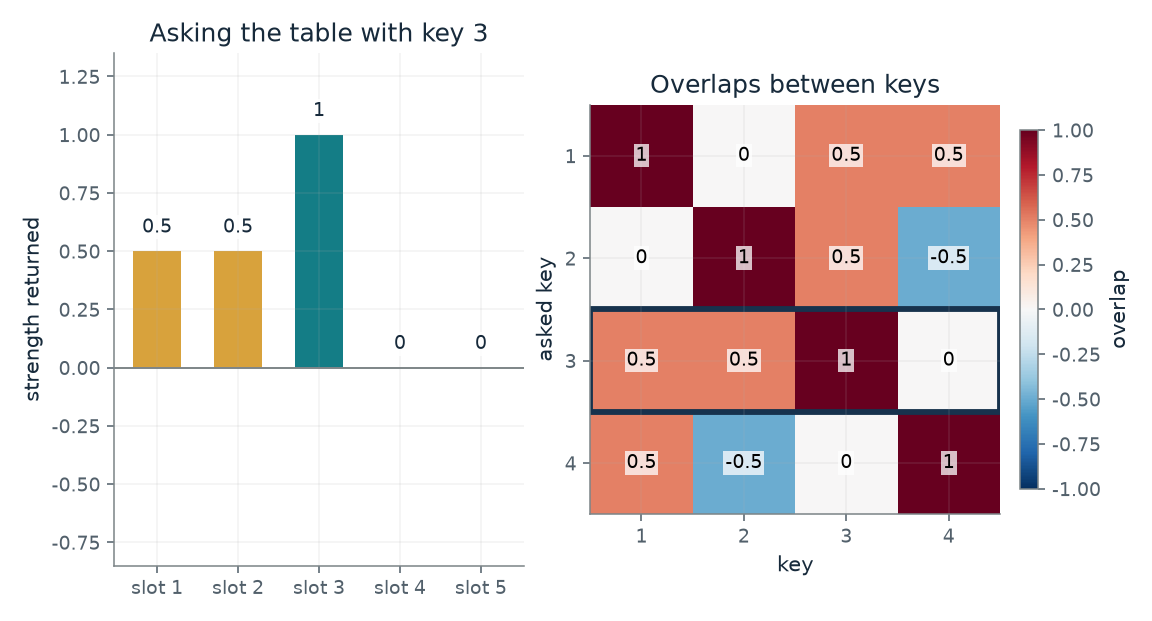

- **Right answer:** 1
- **Ghost slots:** 2
- **Largest ghost:** 0.5
- **Right answer minus largest ghost:** 0.5

With overlapping keys, key 3 returns its own answer at 1 and ghosts: slot 1 gets 0.5, slot 2 gets 0.5. Each ghost equals the overlap of key 3 with that slot's key.

W k3 = v3 + sum of v_i (k_i . k3) over the other keys; here k1.k3 = 0.5, k2.k3 = 0.5, k4.k3 = 0. Own overlap k.k = 1.

In [2]:
figure, values, explanation = ghost_picture(**{'asked': 3, 'keys': 'overlapping'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does asking the table return more than one answer?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Key asked = 3, Key set = overlapping: Key 3 returns its own answer at 1 and two ghosts at one half, in slots 1 and 2, because it overlaps keys 1 and 2 by one half and key 4 by zero. The right answer still wins, by 1 against one half.

**Takeaway:** Every stored pair answers a little. The ghost in a slot is exactly the overlap between the asked key and that slot's key.

**Why it matters:** A table that stores pairs by adding products is clean only when keys are at right angles. Overlap is where edits and old memories interfere.

**In brains and behavior:** The storage rule echoes Hebb's 1949 postulate and Anderson's and Kohonen's 1972 memories. Reading table entries as synapse strengths is the book's analogy, and no brain here is measured.

**In machines:** The table is a specification: this is what an outer-product table returns, by arithmetic. Whether a trained layer behaves like it is a modeling claim.

**Where it applies:** A linear table with unit-length keys and exactly one-hot answers. A trained layer is not this exact; the chapter reads a layer as a key-value table as a working model.

**Check your understanding:** Ask the overlapping table with key 1. Which slots get ghosts, and how strong?

<details><summary>Show the answer</summary>

Key 1 overlaps key 2 by 0, key 3 by one half and key 4 by one half, so slots 3 and 4 each get a ghost of one half and slot 2 gets nothing.

</details>

*Source: Chapter 28, Overlapping keys leave ghosts in each other's answers. Book formula and the chapter's constructed four keys, which are exact fractions. The overlapping set is the chapter's Figure 28.1. The right-angle set is the companion's own, built so every pair of keys has overlap 0.*

## C28-D02: Can a connection weakened by one step be restored by another?

What do a weakening step and a strengthening step do to a table, and what does the toy miss that the rats showed?

Subtracting pair 3's product removes its answer for key 3 and also removes the ghosts it left for keys 1 and 2. Adding the same product back restores the table exactly. On a table that never held the pair, the same add writes the pair outright. That is the point where the toy and the rats differ.

$$
\Delta W=\eta\,v\,k^{\top},\qquad \eta=-1\ \text{(weaken)},\ \ \eta=+1\ \text{(strengthen)}
$$

**Symbols:** Delta W: what one step adds to the table; eta: step size; negative subtracts, as in long-term depression, and positive adds, as in long-term potentiation; v, k: here pair 3's value and key

**Predict before looking:** Subtract pair 3's product from the table, then add it back. Predict whether the table equals the original, and what the same add does to a table that never held pair 3.

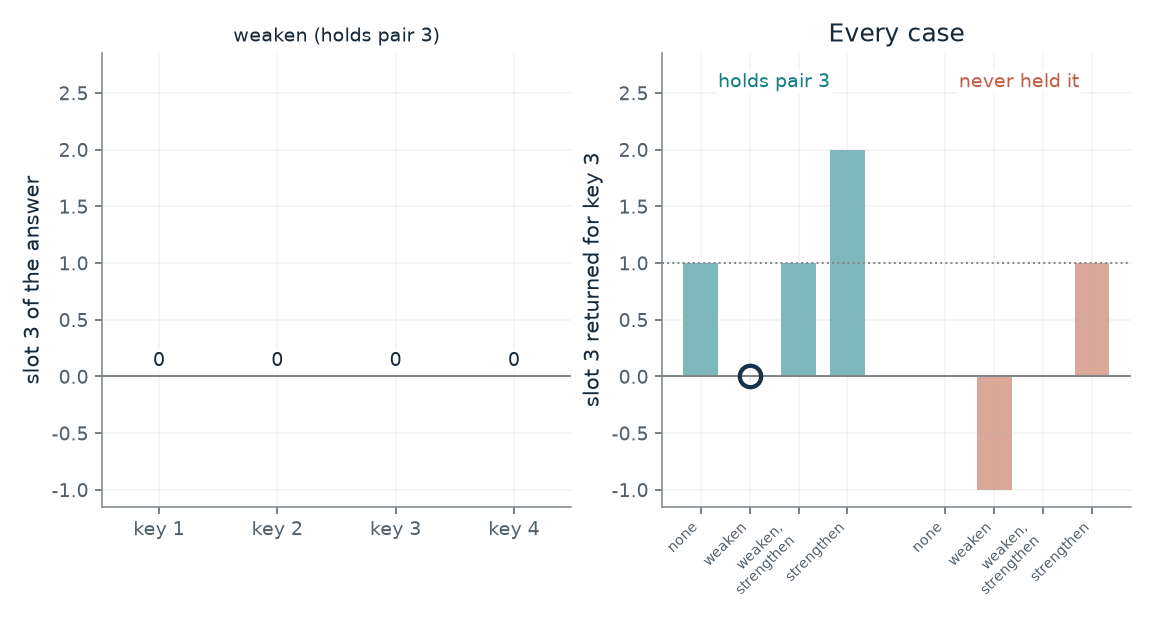

- **Slot 3 for key 3:** 0
- **Slot 3 ghost for key 1:** 0
- **Table equals the starting table:** no
- **Pair 3 answer is:** gone

Operation 'weaken' on a table that holds pair 3 returns 0 in slot 3 for key 3 and 0 for key 1. The table does not equal its starting table.

One step adds eta v3 k3^T with eta = -1 to weaken and +1 to strengthen. Slot 3 for key j is eta (k3 . kj) plus whatever was stored: key 3 gives 0, key 1 gives 0, key 2 gives 0, key 4 gives 0.

In [3]:
figure, values, explanation = weaken_picture(**{'operation': 'weaken', 'case': 'holds pair 3'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can a connection weakened by one step be restored by another?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Operation = weaken then strengthen, Table = holds pair 3: The table returns to the original exactly, and slot 3 for key 3 is 1 again. Switch the table to 'never held pair 3' and choose 'strengthen': the toy writes the pair from nothing. In the rats, fast bursts alone wrote nothing.

**Takeaway:** In the toy a change is exactly undone by its opposite, and the same product also writes the pair from nothing, which the untrained rats did not do.

**Why it matters:** Restoring a weakened response with no new teaching shows something of the pair survived. The toy matches that shape but not the control, so it is a shape and not an explanation.

**In brains and behavior:** Weakening the connections removed the response and strengthening them restored it in the same 12 rats. The authors write the memory was 'inactivated and reactivated,' not erased. Untrained rats showed nothing after fast bursts, and rats whose fear had faded did not get it back. Nothing says a memory in a person can be switched this way.

**In machines:** The toy is a specification of what subtracting and adding an outer product does. Nothing in it stores a memory of what was subtracted; the restoring step must be supplied.

**Where it applies:** Linear table; the weakening product is exactly the one that stored pair 3. A real synapse changes by chemistry over minutes to hours, and the chapter notes the behaving rats were not measured at the synapse.

**Check your understanding:** After weakening only, what do keys 1 and 2 return in slot 3?

<details><summary>Show the answer</summary>

Zero for both. Each had a ghost of one half in slot 3 (their overlap with key 3), and subtracting pair 3's product removes exactly that.

</details>

*Source: Chapter 28, Weakening and then strengthening one set of connections switched a rat's fear response off and on. The toy is the chapter's weaken-and-restore build on its constructed table (exact arithmetic). The rat study is the chapter's account of Nabavi and colleagues (2014): 12 rats, weakening removed the response and strengthening brought it back with no new shock.*

## C28-D03: How much do old pairs feel one new fact?

When one outer product writes a new pair exactly, how much do the old pairs change, and can a better choice of z shrink it?

The leftover v* - W k* is what the table gets wrong for the new key. Writing it along z fixes the new key exactly. An old key feels the write in proportion to its overlap with z. The naive z is the new key, so old keys that overlap it feel it. The corrected z weighs directions by how much the stored keys use them and writes mostly along directions they rarely use.

$$
W'=W+\frac{(v^{*}-Wk^{*})\,z^{\top}}{z^{\top}k^{*}},\qquad z=k^{*}\ \text{(naive)}\ \ \text{or}\ \ z=C^{-1}k^{*}\ \text{(corrected)}
$$

**Symbols:** k*, v*: the new key and the new value; W k*: what the table says for the new key now; z: the direction of the write: it decides which old keys feel it; C: the table of average products of the keys the layer normally sees; here the sum of k k-transpose over the four stored keys

**Predict before looking:** Both writes make the new key return the new answer exactly. Predict whether the corrected write leaves the old pairs untouched, and which does less total damage.

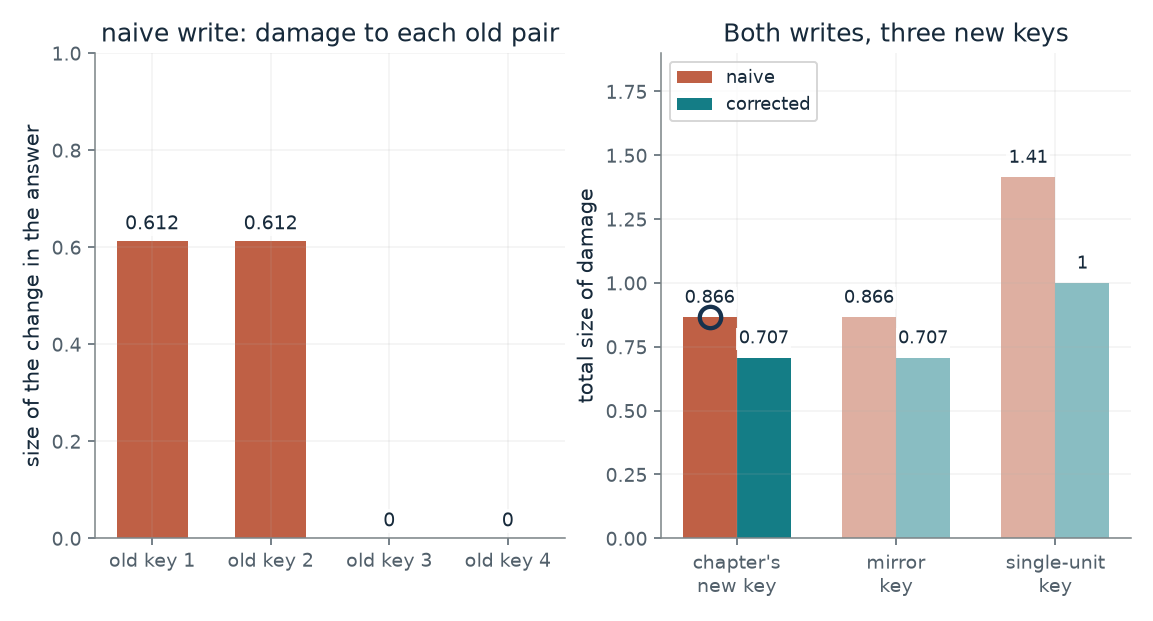

- **Total damage to old pairs:** 0.866
- **Largest single-key change:** 0.612
- **Old keys touched:** 2
- **New key returns slot 5 at:** 1

Both writes make the new key return slot 5 at exactly 1. For the chapter's new key the naive write damages old pairs by 0.866 in total and the corrected write by 0.707, touching 2 old keys in the selected case.

Leftover v* - W k* = [-0.5, -0.5, 0.0, 0.0, 1.0]. Change for old key j is (leftover) times (z . kj) / (z . k*). Total damage = square root of the sum of squared changes = 0.866.

In [4]:
figure, values, explanation = insert_picture(**{'write': 'naive', 'new_key': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much do old pairs feel one new fact?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Write = corrected, New key = 1: The corrected write spreads smaller changes over three old keys, 0.408 each, for a total of 0.707 against 0.866 for the naive write, about 18 percent less. The chapter reports that 0.707 is the smallest any exact update can reach on this table.

**Takeaway:** A well chosen z does not remove the damage. It makes it as small as an exact write allows, and it can move some onto a pair the naive write spared.

**Why it matters:** A new fact written exactly can still disturb old ones. Measuring what an edit does to what it was not meant to touch is a separate test from checking that the edit worked.

**In brains and behavior:** No brain study measured damage to old pairs this way, and there is no evidence a brain computes an update like this one.

**In machines:** In the chapter's account the edit was reported to answer the edited fact 99.8 percent of the time, and 88.1 percent when it was reworded, with unrelated-fact accuracy at 24.2 percent before and after. That aggregate does not show every answer stayed the same.

**Where it applies:** A linear table that already stores the four old pairs exactly, and C taken as exactly the stored keys. The chapter says a trained network does not store old pairs this exactly and that ROME estimates C from 100,000 Wikipedia positions.

**Check your understanding:** In the naive write for the chapter's new key, the leftover is (-0.5, -0.5, 0, 0, 1). Which old keys feel it, and by how much each?

<details><summary>Show the answer</summary>

Keys 1 and 2, because the new key overlaps each by one half and keys 3 and 4 by zero. Each changes by one half of the leftover's length, 0.612, so the total is the square root of two times 0.612 squared, 0.866.

</details>

*Source: Chapter 28, A new fact can be written with one outer product, sized to disturb the old ones as little as possible. Book formula (the write of Meng and colleagues, as the chapter presents it) on the chapter's constructed table. The chapter's new key gives 0.866 and 0.707; the other two keys are the companion's own additions. The language model is not simulated.*

## C28-D04: What happens to a layer after many edits?

If the insert is repeated 20 times, how far does the layer drift, and do the earlier inserts survive?

Each edit adds a rank-one change that fixes the new key and nudges whatever overlaps it. Keys that share a direction all feel each edit, so drift is large and the corrected write helps by writing away from that direction. Unrelated keys feel little, so the correction helps less. In 6 dimensions there is little room: earlier inserts are pushed out sooner, and in this run the correction did not lower drift after 20 edits (about 1.5 corrected against 1.3 naive).

$$
\text{drift}=\frac{\lVert (W-W_0)X\rVert}{\lVert W_0X\rVert},\qquad \text{error}=\sqrt{\tfrac{1}{m}\textstyle\sum_{j}\lVert Wk_j-v_j\rVert^2}
$$

**Symbols:** W_0: the layer before any edit; X: a pool of 256 typical keys; drift: how far the layer's output on typical keys has moved, as a share of its original size; error: root mean square distance of earlier inserts' answers from what they should be

**Predict before looking:** With keys that share a direction, the corrected write cuts drift a lot after one edit. Predict whether it still helps after 20, and whether unrelated keys gain from the correction.

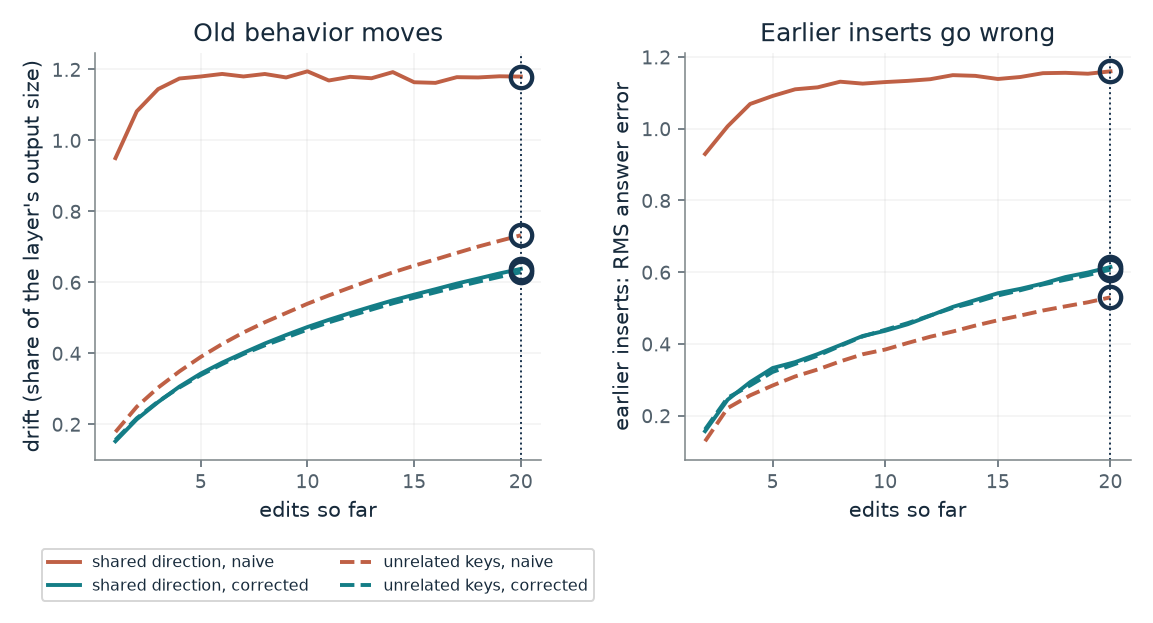

- **Drift, shared keys, naive:** 1.18
- **Drift, shared keys, corrected:** 0.638
- **Earlier-insert error, shared keys, naive:** 1.16
- **Earlier-insert error, shared keys, corrected:** 0.615

After 20 edits in 64 dimensions (mean of 50 seeded runs) drift with keys sharing a direction is 1.18 for the naive write and 0.638 corrected. With unrelated keys it is 0.733 and 0.629. No line stays near zero.

Each edit is W' = W + (v - W k) z^T / (z^T k) with z = k (naive) or z = C^-1 k (corrected, C fixed from 256 sample keys). Drift = |(W - W0) X| / |W0 X| over the same 256 keys X. Error = root mean square of |W k - v| over earlier inserts.

In [5]:
figure, values, explanation = pileup_picture(**{'edits': 20, 'dimension': 64})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What happens to a layer after many edits?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Edits so far = 20, Dimensions = 64: After 20 edits in 64 dimensions, drift is about 1.18 for the naive write and 0.64 for the corrected write with shared keys. With unrelated keys the two writes are close (0.73 against 0.63). Every line ends higher than it starts.

**Takeaway:** The correction counters a shared direction and helps little with unrelated keys, and no line stays near zero. Repeated edits wear a layer down.

**Why it matters:** A single edit that passes its own test says little about the layer after a hundred. Whether old edits survive is its own question.

**In brains and behavior:** No brain study here repeated an edit this way.

**In machines:** Gupta and colleagues, as the chapter reports, found ROME edits began to fail after as few as 100 or as many as 1,000 edits on GPT-J, and a few single edits disabled the model. This toy shows how drift can accumulate, not that it explains those results.

**Where it applies:** A random starting layer, unit random keys and values, C estimated once from the 256-key pool and then held fixed. A simulation is a computation, not a measurement of any language model. The chapter's own caveat applies: edits outnumbering the dimensions cannot all be kept.

**Check your understanding:** In 6 dimensions, how many unit keys can a linear table in principle store exactly if the keys are independent?

<details><summary>Show the answer</summary>

At most 6. Independent keys can be at most as many as the dimensions, so a seventh pair cannot be stored exactly alongside the first six, whatever the write.

</details>

*Source: Chapter 28, The build: three ways to edit a small table. A simulation: the companion's own seeded runs (seeds 1000 to 1049, mean of 50) of the chapter's repeated insert. The chapter's 'shared direction' and 'unrelated' key settings are described in words and the exact code is not in the chapter, so the numbers here are close to but not equal to the chapter's (for example, the chapter reports drift 0.92 and 0.16 after one edit with shared keys; this run gives about 0.95 and 0.15).*

## C28-D05: What does subtracting a direction do at different strengths?

How does the dial c in the Astra-style edit change what a layer writes along a chosen direction?

Each column of the table holds what one neuron writes. The row u-transpose times W says how strongly each column writes along u. The edit scales that row by one minus c in the chosen columns and leaves the rest alone. The change is one outer product, so it has rank at most one.

$$
W'=W-c\,u\,\bigl(m\odot(u^{\top}W)\bigr),\qquad u^{\top}W'=(1-c)\,m\odot(u^{\top}W)+(1-m)\odot(u^{\top}W)
$$

**Symbols:** u: a direction of length 1 in the layer's running list of numbers; u^T W: how strongly each column writes along u; m: ones and zeros that pick which columns are edited; c: the dial: 1 removes the write along u, 2 flips its sign, 6 reverses it and makes it five times larger

**Predict before looking:** Pick the first two neurons and c = 6. Predict the new strengths and say whether the direction is removed.

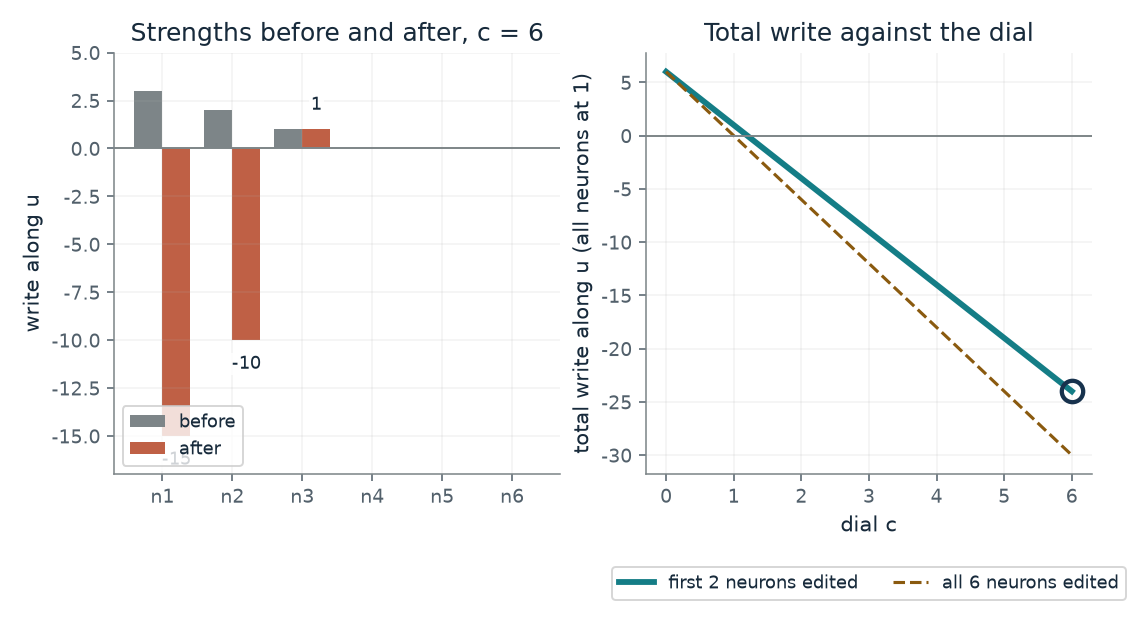

- **Multiplier on chosen columns:** -5
- **Strengths after:** (-15, -10, 1, 0, 0, 0)
- **Total write along u:** -24

At c = 6 the chosen columns' write along u is multiplied by -5, so the strengths become (-15, -10, 1, 0, 0, 0). The total write is -24, against 6 before.

W' = W - c u (m times (u^T W)). Chosen columns: 1 - 6 = -5 times their old strength (3, 2, 1 where chosen). Unchosen columns keep theirs. Sum = -24. The change is one outer product, so its rank is 1.

In [6]:
figure, values, explanation = direction_picture(**{'c': 6, 'columns': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does subtracting a direction do at different strengths?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Dial c = 6, Neurons edited (first n) = 2: The strengths become (-15, -10, 1, 0, 0, 0). The write along u is not removed: it is reversed and made five times larger in the two chosen columns. Setting c = 1 gives (0, 0, 1, 0, 0, 0).

**Takeaway:** The factor on a chosen column's write is 1 minus c. At c = 1 the direction is removed, and at c = 6 it is reversed and five times larger.

**Why it matters:** 'Subtracted that direction' can mean very different edits. Reading the number that sets the strength is part of reading the result.

**In brains and behavior:** None. No brain study applied a rule like this.

**In machines:** A specification: this is what the formula does to a table. Whether the reversal helped is not settled for the final edit.

**Where it applies:** The direction has length 1 and the activity is one for each neuron. The chapter states that Astra chose c = 6 by trial on practice problems and that the final edit was never compared with c = 1.

**Check your understanding:** With all six neurons edited at c = 1 and activity one each, what is the total write along u?

<details><summary>Show the answer</summary>

Zero. Before, 3 + 2 + 1 = 6, and each is multiplied by 1 - 1 = 0. At c = 6 the total is 6 x (1 - 6) = -30.

</details>

*Source: Chapter 28, Subtracting one direction made the repetition rarer, using a stronger setting than plain removal. The chapter's constructed six-neuron example (strengths 3, 2, 1, 0, 0, 0) and its formula. The authors' logs give c = 6 on 64 columns of two tables; plain removal (c = 1) was published earlier by Arditi and colleagues. The layer here has no language in it.*

## C28-D06: Can overshoot calm one loop and break another?

If a layer's output is fed back as input, what does the dial do to a part that grows each round?

The edit scales the growth of the part along u by one minus c. With c = 1 the growth is cancelled, so the multiplier is 1. With c larger than 1 the growth becomes negative, and the multiplier is below 1 and can drop below -1, when the part blows up while flipping sign. The multiplier is stable only while it lies between -1 and 1.

$$
m=1+g\,(1-c),\qquad s_{t+1}=m\,s_t
$$

**Symbols:** g: growth per round of the unedited part along u (0.35 means 35 percent); c: the dial of the direction edit; m: the multiplier the part along u gets each round after the edit; s_t: the size of the part along u after t rounds

**Predict before looking:** At c = 6, predict what happens to a part that grows 35 percent per round, then to one that grows 70 percent.

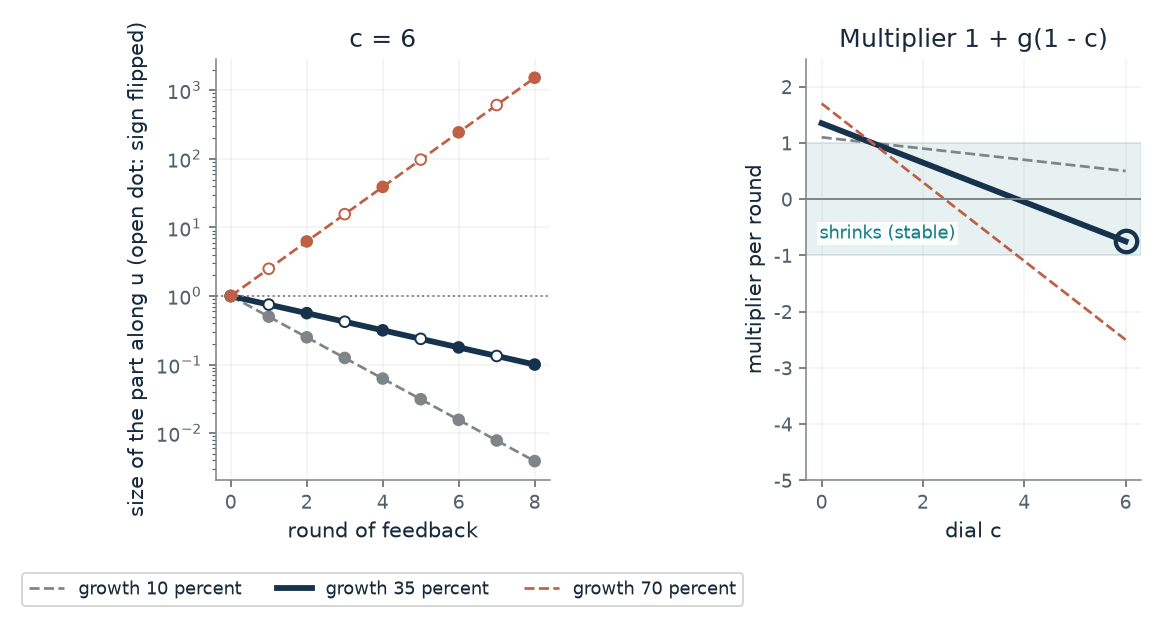

- **Multiplier per round:** -0.75
- **Part along u after 8 rounds:** 0.1
- **Behavior:** shrinks and flips sign each round

With growth 35 percent per round and dial c = 6, the multiplier is -0.75, so the part along u shrinks and flips sign each round. After 8 rounds it is 0.1.

Multiplier = 1 + g(1 - c) = 1 + 0.35 x (1 - 6) = -0.75. After 8 rounds: -0.75^8 = 0.1.

In [7]:
figure, values, explanation = feedback_picture(**{'c': 6, 'growth': 0.35})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can overshoot calm one loop and break another?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Dial c = 6, Growth per round of the unedited part = 0.35: At 35 percent growth the multiplier is -0.75, so the part flips sign each round and shrinks toward zero. Change growth to 0.7 and it becomes -2.5: the part swings in sign and grows. Plain removal (c = 1) holds the part at 1 in both.

**Takeaway:** Overshoot calms a mild loop and breaks a strong one. The multiplier decides, and the toy cannot say which case is Qwen's.

**Why it matters:** A stronger edit than plain removal is not simply 'more removal.' Its effect depends on a number the editor did not choose.

**In machines:** A specification of what repeated multiplication does. It does not show how the real model behaves.

**Where it applies:** The whole signal along u is fed back and multiplied by one factor each round. This is a stand-in for a model reading what it just wrote, not a model of one.

**Check your understanding:** For growth 35 percent, what is the largest c that still gives a multiplier above -1?

<details><summary>Show the answer</summary>

1 + 0.35 (1 - c) = -1 gives 1 - c = -2/0.35 = -5.71, so c = 6.71. Below that the multiplier stays above -1, and c = 6 gives -0.75.

</details>

*Source: Chapter 28, The build: three ways to edit a small table. The chapter's constructed feedback example: growth 35 percent per round gives -0.75 at c = 6, and growth 70 percent gives -2.5. The 10 percent growth is the companion's addition, and the toy cannot say which case describes Qwen.*

## C28-D07: How much of a 40-point gain is new skill?

The edited small model rose from 7.9 to 48.1 percent on MATH-500. What do the other reported scores say about where that came from?

The authors' run raised the score as the share of answers hitting the length limit fell. Three outside groups measured the unedited model with thinking off and got about 44 to 51 percent, a range that includes 48.1. With thinking off, one test moved the edited score about 1.6 points up and another about 2 down. So the headline gain is mostly recovery, and the evidence for new skill is weak.

$$
\text{gain}=\text{score}_{\text{edited}}-\text{score}_{\text{unedited}},\qquad \text{recovered}=\text{score}_{\text{thinking off}}-\text{score}_{\text{thinking on}}
$$

**Symbols:** gain: points added by the edit in the authors' run (thinking on); recovered: points the unedited model already gets when thinking is switched off; passes: the forward-pass budget given to the editor: 10, 25 or 50

**Predict before looking:** Predict whether the unedited model, with thinking switched off, scores nearer 7.9 or nearer 48.1 percent.

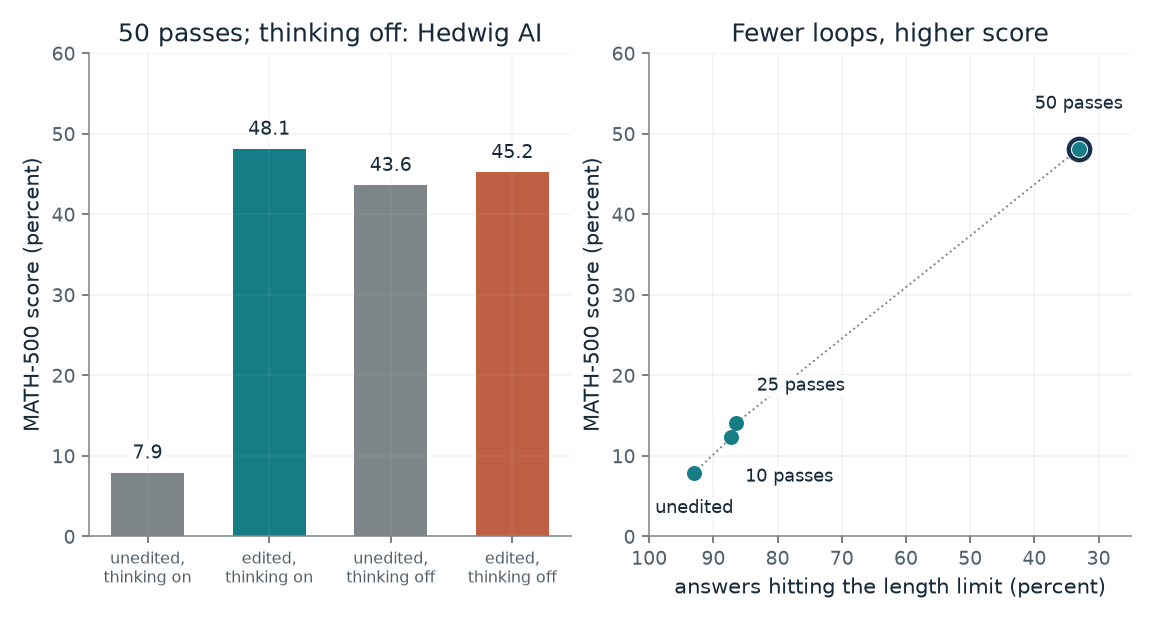

- **Headline gain (points):** 40.2
- **Unedited, thinking off, minus unedited, thinking on:** 35.7
- **Edit's effect with thinking off (points):** 1.6

The 50-pass run raised the score by 40.2 points as the share at the length limit fell to 33.1 percent. The outside check Hedwig AI scored the unedited model 35.7 points above that 7.9 with thinking off, and the edit's effect there was 1.6 points.

Headline gain = 48.1 - 7.9 = 40.2. Thinking-off baseline minus thinking-on baseline = 43.6 - 7.9 = 35.7. The groups used their own graders and answer limits, so these differences are not paired.

In [8]:
figure, values, explanation = astra_picture(**{'passes': 50, 'outside': 'Hedwig AI'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much of a 40-point gain is new skill?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Editor's forward-pass budget = 50, Outside check = Hedwig AI: With thinking off the unedited model scores 43.6 in Hedwig AI's check, nearer 48.1 than 7.9, and the edit's effect there is 1.6 points. EditLens found a drop of about 2 points. Much of the 40.2-point gain looks like recovery from looping settings.

**Takeaway:** Most of the headline gain is recovery from a setting where the model loops. The reported effect of the edit with thinking off is small and points in different directions.

**Why it matters:** A big jump in a score can come from removing an obstacle rather than adding an ability. The chapter's own test on a model that did not loop is a hint, not a matched test.

**In brains and behavior:** None. Brain studies in this chapter changed one narrow thing and none wrote a fact or skill.

**In machines:** A pattern in a handful of unreviewed reports, not proof that repair is easier than teaching. A follow-up preprint reports gains of about 29, 5 and 27 points in three searches and six of 16 attempts ending with the original weights, so one run varies a lot.

**Where it applies:** The groups used their own graders, answer limits and settings, so the scores are not strictly comparable and the differences are not paired. The EditLens unedited figure is quoted in the chapter as 0.510 to 0.512 and 51.0 is used here.

**Check your understanding:** The unedited model scores 43.6 with thinking off in Hedwig AI's check. How far is that above the authors' 7.9, and how much of the 40.2-point headline gain is that?

<details><summary>Show the answer</summary>

43.6 - 7.9 = 35.7 points, which is 35.7 of 40.2, about 89 percent. The scores come from different graders and limits, so the ratio is only a rough guide.

</details>

*Source: Chapter 28, Subtracting one direction made the repetition rarer, using a stronger setting than plain removal. Reported results quoted from the chapter and its notes: the authors' 7.9 to 48.1 percent with the share at the limit 93.0 to 33.1 (10 passes: 12.3 and 87.2; 25 passes: 14.1 and 86.4), and three outside checks with thinking off (Toledo 44.0 unedited; Hedwig AI 43.6 and 45.2; EditLens about 0.51 and 0.487). All are blog-level and unreviewed, with different graders and limits.*

## Bring it to your own question

Check an edit against the old pairs it was not meant to touch, and against a test it was not tuned on, before believing it taught anything.

Use the `mmi-ch28-editing-learned-mind` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.